In [4]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D,MaxPooling2D,Dense,Flatten,Input
from keras.datasets import mnist,fashion_mnist
import keras.backend as be

In [2]:
num_classes = 10

(x_train,y_train),(x_test,y_test) = mnist.load_data()

if be.image_data_format() == "channels_first":
    x_train = x_train.reshape(x_train.shape[0],1,28,28)
    x_test = x_test.reshape(x_test.shape[0],1,28,28)
    shape = (1,28,28)
else:
    x_train = x_train.reshape(x_train.shape[0],28,28,1)
    x_test = x_test.reshape(x_test.shape[0],28,28,1)
    shape = (28,28,1)

x_train = x_train/255.
x_test = x_test/255.

y_train = keras.utils.to_categorical(y_train,num_classes)
y_test = keras.utils.to_categorical(y_test,num_classes)

y_test


array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [5]:
model = Sequential([
    Input(shape),
    Conv2D(64,activation="relu",kernel_size=(3,3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64,activation="relu",kernel_size=(3,3)),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(num_classes,activation="softmax")])

In [6]:
model.compile(optimizer="adam",loss="categorical_crossentropy",
                metrics=["accuracy"])
model.fit(x_train,y_train,epochs=10,batch_size=128)



Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8339 - loss: 0.5692
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9784 - loss: 0.0713
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9839 - loss: 0.0512
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9875 - loss: 0.0409
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9899 - loss: 0.0334
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9905 - loss: 0.0309
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9925 - loss: 0.0250
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9931 - loss: 0.0221
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9946 - loss: 0.0173
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9954 - loss: 0.0155


In [7]:
print(model.evaluate(x_test,y_test))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9877 - loss: 0.0389
[0.03107588179409504, 0.9904000163078308]


In [8]:
model.predict(x_test[0:1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


array([[2.6249215e-12, 1.3276702e-12, 1.6469362e-07, 6.4016483e-08,
        1.8455038e-12, 1.0696027e-11, 8.3154522e-20, 9.9999976e-01,
        1.4538075e-10, 5.1843778e-09]], dtype=float32)

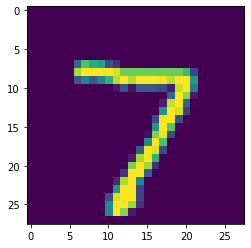

In [14]:
imshow(x_test[0].reshape((28,28)))

In [15]:
def model_init_train(kernel,pool):
    model = Sequential([
        Input(shape),
        Conv2D(64,activation="relu",kernel_size=kernel),
        MaxPooling2D(pool_size=pool),
        Conv2D(64,activation="relu",kernel_size=kernel),
        MaxPooling2D(pool_size=pool),
        Flatten(),
        Dense(num_classes,activation="softmax")])
    model.compile(optimizer="adam",loss="categorical_crossentropy",
                metrics=["accuracy"])
    model.fit(x_train,y_train,epochs=10,batch_size=128)
    print(kernel,pool,model.evaluate(x_test,y_test))
    return model

In [16]:
mdls = {}
for shp in shapes:
    for pool in shapes:
        mdls[(shp,pool)]=model_init_train(shp,pool)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7915 - loss: 0.6822
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9724 - loss: 0.0943
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9797 - loss: 0.0671
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9833 - loss: 0.0531
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9864 - loss: 0.0447
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9884 - loss: 0.0388
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9895 - loss: 0.0356
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9897 - loss: 0.0318
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9910 - loss: 0.0278
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9939 - loss: 0.0213
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 906us/step - accuracy: 0.9827 - loss: 0.0578
(2, 2) (2, 2) [0.04578898474574089, 0.9864000082015991]
Epoch 

ValueError: Exception encountered when calling MaxPooling2D.call().

[1mNegative dimension size caused by subtracting 4 from 3 for '{{node sequential_30_1/max_pooling2d_61_1/MaxPool2d}} = MaxPool[T=DT_FLOAT, data_format="NHWC", explicit_paddings=[], ksize=[1, 4, 4, 1], padding="VALID", strides=[1, 4, 4, 1]](sequential_30_1/conv2d_61_1/Relu)' with input shapes: [?,3,3,64].[0m

Arguments received by MaxPooling2D.call():
  • inputs=tf.Tensor(shape=(None, 3, 3, 64), dtype=float32)

In [13]:
shapes = [(2,2),(3,3),(3,2),(2,3),(4,4)]

In [22]:

[  (k,v.evaluate(x_test,y_test)[1]) for k,v in mdls.items()]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9827 - loss: 0.0578
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 706us/step - accuracy: 0.9726 - loss: 0.0867
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step - accuracy: 0.9785 - loss: 0.0710
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step - accuracy: 0.9816 - loss: 0.0586
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 575us/step - accuracy: 0.9372 - loss: 0.1922
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9864 - loss: 0.0424
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 759us/step - accuracy: 0.9796 - loss: 0.0571
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - accuracy: 0.9847 - loss: 0.0502
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step - accuracy: 0.9868 - loss: 0.0413
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 671us/step - accuracy: 0.9789 - loss: 0.0618
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9839 - loss: 0.0466
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.9802 - loss: 0.0608
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - accuracy: 0.9784 - loss: 0.0707
313/3

[(((2, 2), (2, 2)), 0.9864000082015991),
 (((2, 2), (3, 3)), 0.9778000116348267),
 (((2, 2), (3, 2)), 0.9812999963760376),
 (((2, 2), (2, 3)), 0.9843000173568726),
 (((2, 2), (4, 4)), 0.9465000033378601),
 (((3, 3), (2, 2)), 0.9887999892234802),
 (((3, 3), (3, 3)), 0.9858999848365784),
 (((3, 3), (3, 2)), 0.9869999885559082),
 (((3, 3), (2, 3)), 0.9907000064849854),
 (((3, 3), (4, 4)), 0.9828000068664551),
 (((3, 2), (2, 2)), 0.987500011920929),
 (((3, 2), (3, 3)), 0.9843999743461609),
 (((3, 2), (3, 2)), 0.982699990272522),
 (((3, 2), (2, 3)), 0.98580002784729),
 (((3, 2), (4, 4)), 0.9735000133514404),
 (((2, 3), (2, 2)), 0.989300012588501),
 (((2, 3), (3, 3)), 0.9824000000953674),
 (((2, 3), (3, 2)), 0.9843000173568726),
 (((2, 3), (2, 3)), 0.988099992275238),
 (((2, 3), (4, 4)), 0.9733999967575073),
 (((4, 4), (2, 2)), 0.991599977016449),
 (((4, 4), (3, 3)), 0.9815000295639038),
 (((4, 4), (3, 2)), 0.9846000075340271),
 (((4, 4), (2, 3)), 0.9853000044822693)]